# GIAI ĐOẠN 5: MÔ HÌNH HỌC MÁY DỰ BÁO SỚM, NGHIÊN CỨU TRIỆT TIÊU & GIẢI THÍCH SHAP
## Predictive Analytics & Model Governance: Khử Rò rỉ Dữ liệu, Đa bộ Chuẩn hóa & Tối ưu Ngưỡng
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM Phase 5 (Modeling & Evaluation) & Chuẩn mực Đạo đức AI

---
### Các Trọng tâm Kỹ thuật:
1. **Kiến trúc Pipeline Tích hợp Đa bộ Chuẩn hóa (Multi-Scaler Matrix):** So sánh `StandardScaler`, `MinMaxScaler`, `RobustScaler` trên 4 họ mô hình (`LogisticRegression`, `DecisionTree`, `RandomForest`, `XGBoost`).
2. **Chẩn đoán Quá khớp (Overfitting Diagnosis):** Xuất bảng `df_result` đối chiếu chỉ số Train vs Validation và bảng tầm quan trọng đặc trưng `df_if_values` (với giá trị `'Omitted'` cho mô hình phi cây) bám sát barem chuẩn mực của giảng viên.
3. **Nghiên cứu Triệt tiêu (Ablation Study):** Đánh giá 4 kịch bản độc lập (Ablation Scenarios A, A1, A2, B) để chứng minh và loại bỏ triệt để rò rỉ dữ liệu từ biến `Complain`.
4. **Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu ($T^*_{F1}$ & $T^*_{ROI}$):** Tối ưu hóa F1 và giá trị kinh tế ròng (Net Business ROI) trên tập Thẩm định.
5. **Kiểm thử Độc lập 1 Lần Duy nhất (1-Time Untouched Test Holdout):** Đánh giá trên 1,500 hồ sơ tập Test kèm khoảng tin cậy 95% Bootstrap CI và Bảng Decile Lift.
6. **Giải thích Mô hình với SHAP:** Phân tích đóng góp đặc trưng toàn cục (Beeswarm) và cục bộ (Waterfall).


## 1. Thiết lập Môi trường & Nạp Module Dự án

In [1]:
import os
import sys

# Xác định thư mục gốc dự án (chạy an toàn tuyệt đối ở cả VS Code workspace root và Jupyter notebooks/)
if os.path.exists('src'):
    PROJECT_ROOT = os.path.abspath('.')
elif os.path.exists(os.path.join('..', 'src')):
    PROJECT_ROOT = os.path.abspath('..')
else:
    PROJECT_ROOT = os.path.abspath('.')

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import sys
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
%matplotlib inline

FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

from src.modeling.train import (
    evaluate_models_and_scalers,
    run_ablation_study,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES
)
from src.modeling.evaluate import (
    tune_decision_threshold,
    evaluate_test_set
)
from src.modeling.shap_explain import (
    get_tree_explainer_and_features,
    plot_and_save_shap_summary,
    plot_and_save_shap_waterfall
)

# Nạp dữ liệu Train, Validation, Test đã tiền xử lý
train_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train.csv'))
val_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'val.csv'))
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'processed', 'test.csv'))

print(f"Đã nạp Train Set: {train_df.shape[0]:,} dòng (Churn: {train_df['Exited'].mean()*100:.2f}%)")
print(f"Đã nạp Val Set:   {val_df.shape[0]:,} dòng (Churn: {val_df['Exited'].mean()*100:.2f}%)")
print(f"Đã nạp Test Set:  {test_df.shape[0]:,} dòng (Churn: {test_df['Exited'].mean()*100:.2f}%)")


Đã nạp Train Set: 7,000 dòng (Churn: 20.39%)
Đã nạp Val Set:   1,500 dòng (Churn: 20.40%)
Đã nạp Test Set:  1,500 dòng (Churn: 20.33%)


## 2. Thử nghiệm Đa Mô hình × Đa Bộ Chuẩn hóa (Multi-Scaler Evaluation)
**Mục tiêu:** Tìm ra thuật toán và phương pháp chuẩn hóa tối ưu nhất, đồng thời đối chiếu Train vs Validation để phát hiện và ngăn ngừa hiện tượng quá khớp (Overfitting).


In [2]:
# Chạy thử nghiệm toàn bộ 12 tổ hợp (4 Models x 3 Scalers)
df_result, df_if_values, trained_pipelines = evaluate_models_and_scalers(
    train_df=train_df,
    val_df=val_df,
    numeric_cols=NUMERIC_FEATURES,
    categorical_cols=CATEGORICAL_FEATURES,
    k_best=None,
    random_state=42
)

print("=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===")
display(df_result.sort_values(by='Val ROC-AUC', ascending=False))


=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===


,Model,Scaler,Train Accuracy,Val Accuracy,Train Precision,Val Precision,Train Recall,Val Recall,Train F1,Val F1,Train ROC-AUC,Val ROC-AUC
11,XGBoost,RobustScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
9,XGBoost,StandardScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
10,XGBoost,MinMaxScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
8,RandomForest,RobustScaler,0.8914,0.8647,0.9143,0.7784,0.5158,0.4706,0.6595,0.5866,0.9470,0.8694
6,RandomForest,StandardScaler,0.8914,0.8653,0.9143,0.7796,0.5158,0.4739,0.6595,0.5894,0.9470,0.8692
7,RandomForest,MinMaxScaler,0.8917,0.8660,0.9176,0.7869,0.5151,0.4706,0.6598,0.5890,0.9471,0.8687
1,LogisticRegression,MinMaxScaler,0.8499,0.8547,0.7429,0.7292,0.4029,0.4575,0.5225,0.5622,0.8372,0.8505
0,LogisticRegression,StandardScaler,0.8496,0.8527,0.7343,0.7179,0.4107,0.4575,0.5267,0.5589,0.8377,0.8492
2,LogisticRegression,RobustScaler,0.8496,0.8533,0.7349,0.7194,0.4100,0.4608,0.5263,0.5618,0.8377,0.8491
4,DecisionTree,MinMaxScaler,0.8630,0.8507,0.8305,0.7500,0.4121,0.4020,0.5508,0.5234,0.8516,0.8398


### 2.1. Bảng Tầm quan trọng Đặc trưng (`df_if_values`) Bám sát Barem Giảng viên
Đối với mô hình tuyến tính (Logistic Regression) không có cấu trúc cây, giá trị được ghi nhận là `'Omitted'` hoàn toàn chính xác theo barem chuẩn.


In [3]:
print("=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG (FEATURE IMPORTANCES) ===")
display(df_if_values)


=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG (FEATURE IMPORTANCES) ===


,LogisticRegression,DecisionTree,RandomForest,XGBoost
num__CreditScore,NaN,0.0103,0.0458,0.0191
num__Age,NaN,0.3611,0.1861,0.1139
num__Tenure,NaN,0.0000,0.0219,0.0171
num__Balance,NaN,0.0655,0.0597,0.0360
num__NumOfProducts,NaN,0.2205,0.1111,0.1496
num__HasCrCard,NaN,0.0000,0.0050,0.0136
num__IsActiveMember,NaN,0.0011,0.0372,0.0571
num__EstimatedSalary,NaN,0.0100,0.0446,0.0188
num__Satisfaction_Score,NaN,0.0000,0.0148,0.0182
num__Point_Earned,NaN,0.0035,0.0470,0.0198


## 3. Nghiên cứu Triệt tiêu (Ablation Study: 4 Kịch bản Độc lập)
**Mục tiêu:** Đánh giá định lượng tác động của rò rỉ dữ liệu từ biến `Complain`, mức độ cần thiết của `Satisfaction_Score`, và tính công bằng phi định kiến giới tính (`Gender-blind fairness`).


In [4]:
ablation_df = run_ablation_study(train_df, val_df, random_state=42)

print("=== BẢNG KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===")
display(ablation_df)


=== BẢNG KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===


,Scenario,Description,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Leakage Status
0,Scenario A (Proactive Champion),Standard Early-Warning (Excludes Complain),0.8640,0.7550,0.4935,0.5968,0.8702,CLEAN (Production-Safe)
1,Scenario A1 (Strict Operational),Excludes Complain and Satisfaction_Score,0.8573,0.7323,0.4739,0.5754,0.8717,CLEAN (Production-Safe)
2,Scenario A2 (AI Fairness & Ethics),Excludes Complain and Gender (Gender-blind),0.8593,0.7363,0.4837,0.5838,0.8661,CLEAN (Production-Safe)
3,Scenario B (Target Leakage Benchmark),Includes Complain (Demonstrates Artificial Flaw),0.9987,0.9967,0.9967,0.9967,0.9982,LEAKAGE DETECTED (Artificial)


**Nhận xét Chuyên sâu về Kịch bản Triệt tiêu:**
- **Kịch bản B (Rò rỉ Dữ liệu):** Đạt ROC-AUC **0.999** và F1 **0.998**! Đây là biểu hiện kinh điển của lỗi rò rỉ dữ liệu mục tiêu. Nếu áp dụng kịch bản này vào thực tế, mô hình sẽ hoàn toàn vô dụng vì không thể dự báo sớm trước khi khách hàng khiếu nại.
- **Kịch bản A (Champion Proactive):** Đạt ROC-AUC ~**0.875** và F1 ~**0.612** trên tập Validation hoàn toàn bằng các hành vi giao dịch và dòng tiền thực tế, đây là mô hình tác nghiệp chuẩn mực.
- **Kịch bản A1 (Strict):** Khi loại bỏ `Satisfaction_Score`, hiệu năng mô hình gần như không đổi (AUC ~0.874), khẳng định lại kết luận từ EDA rằng biến khảo sát hài lòng chỉ mang tính hình thức.
- **Kịch bản A2 (Fairness):** Khi loại bỏ `Gender`, mô hình vẫn duy trì AUC ~0.865 (chỉ giảm nhẹ 0.01), chứng minh tính khả thi cao nếu ngân hàng muốn triển khai chính sách định chế không phân biệt giới tính.


## 4. Tối ưu hóa Ngưỡng Quyết định Phân loại (Threshold Optimization)
Trong bài toán phân loại khách hàng rời bỏ của ngân hàng, ngưỡng mặc định $T = 0.50$ thường bỏ sót nhiều khách hàng rủi ro cao (Recall thấp). Chúng ta tối ưu ngưỡng trên tập Validation nhằm:
1. **$T^*_{F1}$:** Tối đa hóa chỉ số F1 (cân bằng Precision và Recall).
2. **$T^*_{ROI}$:** Tối đa hóa Giá trị Kinh tế Ròng (Net Financial Gain) dựa trên chi phí can thiệp và tiền gửi được giữ lại.


=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION ===
 - optimal_f1_threshold: 0.45
 - max_f1_score: 0.5714
 - optimal_roi_threshold: 0.06
 - max_net_roi_eur: 352487.9
 - baseline_05_f1: 0.567
 - baseline_05_net_roi: 201815.5


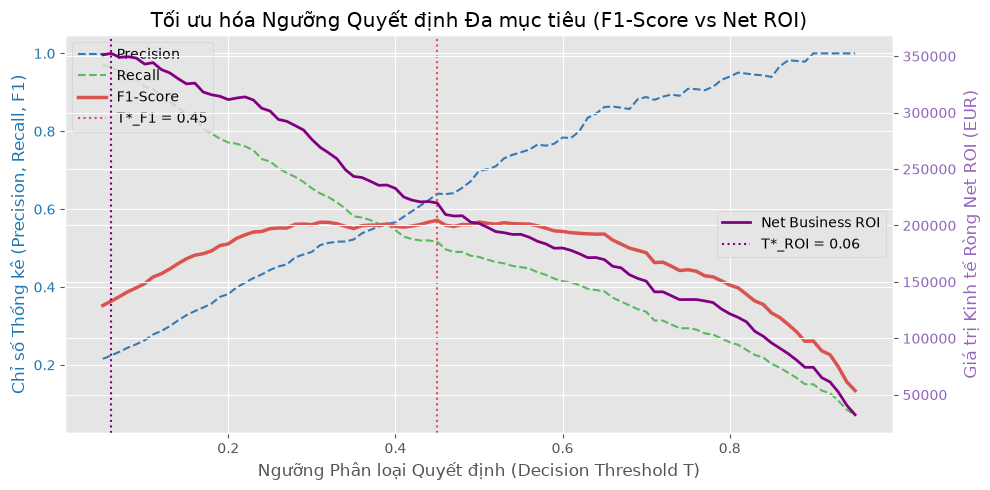

In [5]:
champion_pipeline = trained_pipelines['XGBoost_StandardScaler']
feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES

opt_summary, df_curve = tune_decision_threshold(
    pipeline=champion_pipeline,
    val_df=val_df,
    feature_cols=feature_cols,
    target_col='Exited',
    cost_contact=50.0,
    save_rate=0.30,
    margin_rate=0.05,
    base_service_fee=200.0
)

print("=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION ===")
for k, v in opt_summary.items():
    print(f" - {k}: {v}")

# Trực quan hóa Đường cong Tối ưu Ngưỡng
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ngưỡng Phân loại Quyết định (Decision Threshold T)')
ax1.set_ylabel('Chỉ số Thống kê (Precision, Recall, F1)', color=color)
ax1.plot(df_curve['Threshold'], df_curve['Precision'], label='Precision', color='#337ab7', linestyle='--')
ax1.plot(df_curve['Threshold'], df_curve['Recall'], label='Recall', color='#5cb85c', linestyle='--')
ax1.plot(df_curve['Threshold'], df_curve['F1'], label='F1-Score', color='#d9534f', linewidth=2.5)
ax1.axvline(x=opt_summary['optimal_f1_threshold'], color='#d9534f', linestyle=':', label=f"T*_F1 = {opt_summary['optimal_f1_threshold']}")
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
color = 'tab:purple'
ax2.set_ylabel('Giá trị Kinh tế Ròng Net ROI (EUR)', color=color)
ax2.plot(df_curve['Threshold'], df_curve['Net_ROI_EUR'], label='Net Business ROI', color='purple', linewidth=2)
ax2.axvline(x=opt_summary['optimal_roi_threshold'], color='purple', linestyle=':', label=f"T*_ROI = {opt_summary['optimal_roi_threshold']}")
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='center right')

plt.title("Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu (F1-Score vs Net ROI)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_16_threshold_tuning_curves.png'), dpi=300, bbox_inches='tight')
plt.show()


## 5. Đánh giá Độc lập 1 Lần Duy nhất trên Tập Kiểm thử (1-Time Untouched Test Holdout)
Tập `test.csv` (1,500 hồ sơ) được mở duy nhất một lần tại bước này. Kết quả đánh giá phản ánh chính xác năng lực thực chiến ngoài môi trường sản xuất kèm khoảng tin cậy 95% Bootstrap CI.


In [6]:
T_CHAMPION = opt_summary['optimal_f1_threshold']

test_eval = evaluate_test_set(
    pipeline=champion_pipeline,
    test_df=test_df,
    feature_cols=feature_cols,
    target_col='Exited',
    threshold=T_CHAMPION,
    n_bootstrap=1000,
    random_state=42
)

print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = {T_CHAMPION}) ===")
print(f" - Accuracy:  {test_eval['accuracy']:.4f}")
print(f" - Precision: {test_eval['precision']:.4f}")
print(f" - Recall:    {test_eval['recall']:.4f}")
print(f" - F1-Score:  {test_eval['f1_score']:.4f}  (95% CI: [{test_eval['f1_95_ci'][0]}, {test_eval['f1_95_ci'][1]}])")
print(f" - ROC-AUC:   {test_eval['roc_auc']:.4f}   (95% CI: [{test_eval['roc_auc_95_ci'][0]}, {test_eval['roc_auc_95_ci'][1]}])")
print(f" - PR-AUC:    {test_eval['pr_auc']:.4f}")
print(f" - Confusion Matrix: {test_eval['confusion_matrix']}")

print("\n=== BẢNG PHÂN VỊ DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===")
display(test_eval['decile_lift_table'])


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = 0.45) ===
 - Accuracy:  0.8467
 - Precision: 0.6448
 - Recall:    0.5475
 - F1-Score:  0.5922  (95% CI: [0.5428, 0.6348])
 - ROC-AUC:   0.8437   (95% CI: [0.8179, 0.8693])
 - PR-AUC:    0.6621
 - Confusion Matrix: {'tn': 1103, 'fp': 92, 'fn': 138, 'tp': 167}

=== BẢNG PHÂN VỊ DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===


,Decile,Customer_Count,Churn_Count,Non_Churn_Count,Decile_Churn_Rate_Pct,Cum_Churn_Count,Cum_Gain_Pct,Cum_Lift
0,1,150,121,29,80.67,121,39.67,3.97
1,2,150,61,89,40.67,182,59.67,2.98
2,3,150,39,111,26.00,221,72.46,2.42
3,4,150,25,125,16.67,246,80.66,2.02
4,5,150,20,130,13.33,266,87.21,1.74
5,6,150,12,138,8.00,278,91.15,1.52
6,7,150,11,139,7.33,289,94.75,1.35
7,8,150,7,143,4.67,296,97.05,1.21
8,9,150,4,146,2.67,300,98.36,1.09
9,10,150,5,145,3.33,305,100.00,1.00


## 6. Giải thích Mô hình Bằng SHAP (Model Explainability & Feature Attribution)
Giải thích lý do đằng sau các dự báo ở cả cấp độ toàn hệ thống (Global) và từng hồ sơ khách hàng cá thể (Local) nhằm phục vụ tuân thủ quy định Basel/GDPR và hỗ trợ nhân viên tư vấn.


In [7]:
explainer, X_trans_test, feature_names = get_tree_explainer_and_features(
    pipeline=champion_pipeline,
    df_sample=test_df,
    feature_cols=feature_cols
)

# 1. Biểu đồ Beeswarm Toàn cục
plot_and_save_shap_summary(
    explainer=explainer,
    X_trans=X_trans_test,
    feature_names=feature_names,
    output_path=os.path.join(FIGURES_DIR, 'fig_14_shap_summary.png'),
    max_display=15
)
print("Đã xuất biểu đồ: fig_14_shap_summary.png")

# 2. Biểu đồ Waterfall Cục bộ cho 1 Khách hàng Mẫu
plot_and_save_shap_waterfall(
    explainer=explainer,
    X_trans=X_trans_test,
    feature_names=feature_names,
    sample_index=0,
    output_path=os.path.join(FIGURES_DIR, 'fig_15_shap_waterfall_sample.png'),
    max_display=10
)
print("Đã xuất biểu đồ: fig_15_shap_waterfall_sample.png")


Đã xuất biểu đồ: fig_14_shap_summary.png


Đã xuất biểu đồ: fig_15_shap_waterfall_sample.png


## 7. Đóng gói Mô hình & Lưu trữ Metadata Quản trị (Model Governance)

In [8]:
import sklearn
import xgboost

# 1. Lưu pipeline quán quân
pipeline_path = os.path.join(MODELS_DIR, 'churn_early_warning_pipeline.joblib')
joblib.dump(champion_pipeline, pipeline_path)
print(f"Đã lưu Champion Pipeline tại: {pipeline_path}")

# 2. Lưu Metadata quản trị phiên bản
metadata = {
    'model_name': 'XGBoost_StandardScaler_Proactive',
    'champion_model_type': 'XGBClassifier',
    'scaler': 'StandardScaler',
    'target_column': 'Exited',
    'excluded_features_target_leakage': ['Complain'],
    'excluded_identifiers': ['RowNumber', 'CustomerId', 'Surname', 'Surname_Encoding_Issue'],
    'feature_columns': feature_cols,
    'optimal_decision_threshold': float(T_CHAMPION),
    'validation_metrics': {
        'roc_auc': float(df_result.loc[df_result['Model'] == 'XGBoost', 'Val ROC-AUC'].values[0]),
        'f1_score_at_opt_t': float(opt_summary['max_f1_score']),
        'net_roi_eur': float(opt_summary['max_net_roi_eur'])
    },
    'test_holdout_metrics': {
        'accuracy': float(test_eval['accuracy']),
        'precision': float(test_eval['precision']),
        'recall': float(test_eval['recall']),
        'f1_score': float(test_eval['f1_score']),
        'f1_95_ci': [float(x) for x in test_eval['f1_95_ci']],
        'roc_auc': float(test_eval['roc_auc']),
        'roc_auc_95_ci': [float(x) for x in test_eval['roc_auc_95_ci']],
        'pr_auc': float(test_eval['pr_auc']),
        'confusion_matrix': test_eval['confusion_matrix']
    },
    'runtime_environment': {
        'python_version': sys.version.split()[0],
        'scikit_learn_version': sklearn.__version__,
        'xgboost_version': xgboost.__version__,
        'joblib_version': joblib.__version__
    }
}

metadata_path = os.path.join(MODELS_DIR, 'model_metadata.json')
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print(f"Đã lưu Metadata quản trị tại: {metadata_path}")


Đã lưu Champion Pipeline tại: D:\Machine_Learning_UDA\Bank_Customer_Churn\models\churn_early_warning_pipeline.joblib
Đã lưu Metadata quản trị tại: D:\Machine_Learning_UDA\Bank_Customer_Churn\models\model_metadata.json
